# Final comparison graphs

Final test-set comparisons for the small and large MovieLens datasets. This notebook uses saved numerical results and does not train the models again.

In [4]:
import matplotlib.pyplot as plt
import pandas as pd


def add_value_labels(ax, bars, decimals):
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f'{height:.{decimals}f}',
            ha='center',
            va='bottom',
            fontsize=10,
        )


## ML-Latest Small

Results and hyperparameters are taken from `final_ml-latest-small_models.ipynb`.

In [5]:
model_names = [
    'Baseline',
    'Hard Thresholding',
    'Soft Thresholding',
    'Gradient Descent',
    'SGD',
    'ALS',
]

test_rmse_values = [
    1.0488405992661316,
    0.8877206384988603,
    0.8702908977602052,
    0.9043744153856905,
    0.892508,
    0.8965515139968124,
]

test_mae_values = [
    0.8315907281547353,
    0.6825784740314891,
    0.6771797737994913,
    0.6951518143834174,
    0.681769,
    0.6867641937441624,
]



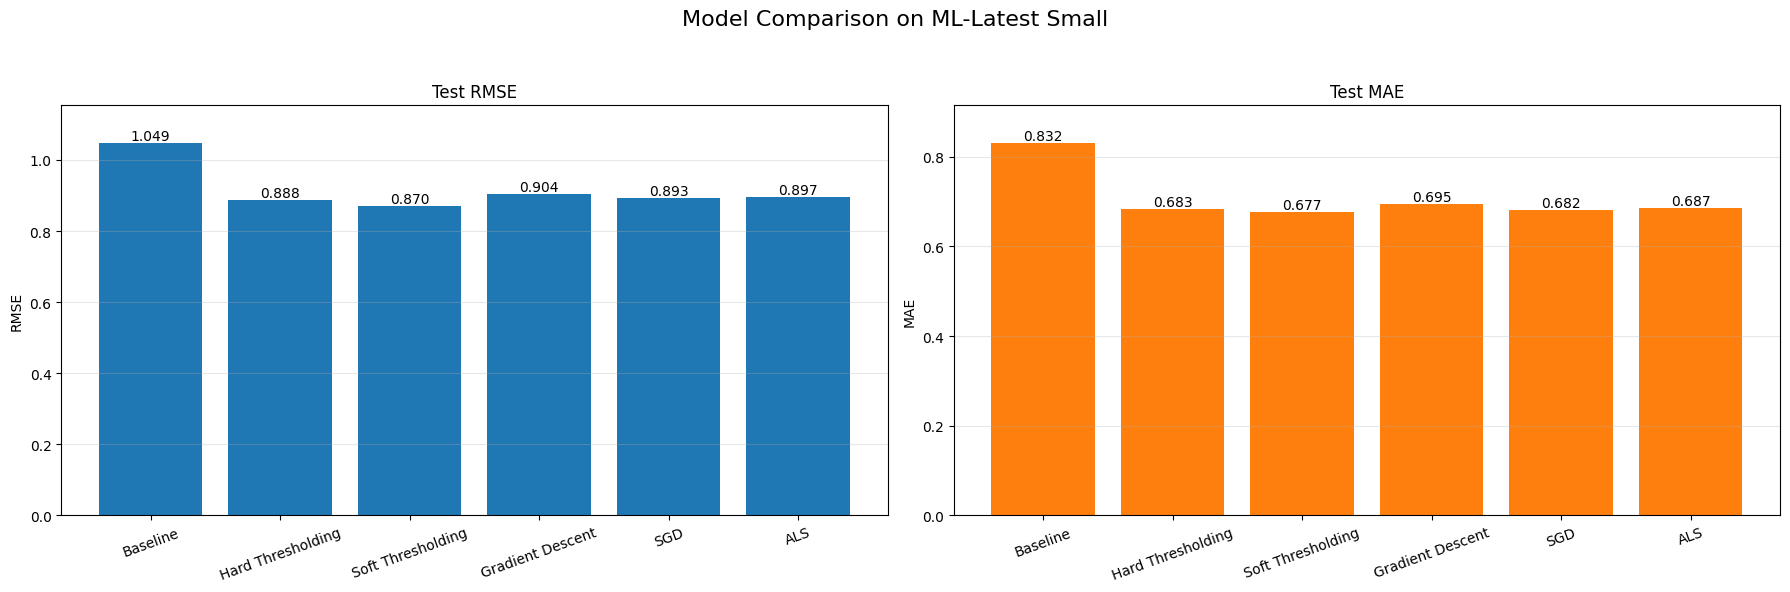

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Model Comparison on ML-Latest Small', fontsize=16)

rmse_bars = axes[0].bar(model_names, test_rmse_values, color='tab:blue')
axes[0].set_title('Test RMSE')
axes[0].set_ylabel('RMSE')
axes[0].set_ylim(0, max(test_rmse_values) * 1.10)
axes[0].grid(axis='y', alpha=0.3)
axes[0].tick_params(axis='x', rotation=20)
add_value_labels(axes[0], rmse_bars, decimals=3)

mae_bars = axes[1].bar(model_names, test_mae_values, color='tab:orange')
axes[1].set_title('Test MAE')
axes[1].set_ylabel('MAE')
axes[1].set_ylim(0, max(test_mae_values) * 1.10)
axes[1].grid(axis='y', alpha=0.3)
axes[1].tick_params(axis='x', rotation=20)
add_value_labels(axes[1], mae_bars, decimals=3)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


## ML-Latest

Hard Thresholding and Gradient Descent results come from the executed Fritz HPC notebooks. Baseline, ALS, and SGD results come from `final_ml_latest_models.ipynb`.

In [7]:
large_results = pd.DataFrame({
    'model': ['Baseline', 'Hard Thresholding', 'Gradient Descent', 'SGD', 'ALS'],
    'test_rmse': [1.0642243146026569, 0.799608, 0.800672, 0.7991385276147324, 0.7931],
    'test_mae': [0.8431218080817922, 0.598560, 0.600007, 0.5989681125102329, 0.5936],
    'source': [
        'final_ml_latest_models.ipynb',
        'hard_thresholding_final_training_hpc_executed.ipynb',
        'gd_final_training_hpc_executed.ipynb',
        'final_ml_latest_models.ipynb',
        'final_ml_latest_models.ipynb',
    ],
})

large_results


,model,test_rmse,test_mae,source
0,Baseline,1.064224,0.843122,final_ml_latest_models.ipynb
1,Hard Thresholding,0.799608,0.598560,hard_thresholding_final_training_hpc_executed....
2,Gradient Descent,0.800672,0.600007,gd_final_training_hpc_executed.ipynb
3,SGD,0.799139,0.598968,final_ml_latest_models.ipynb
4,ALS,0.793100,0.593600,final_ml_latest_models.ipynb


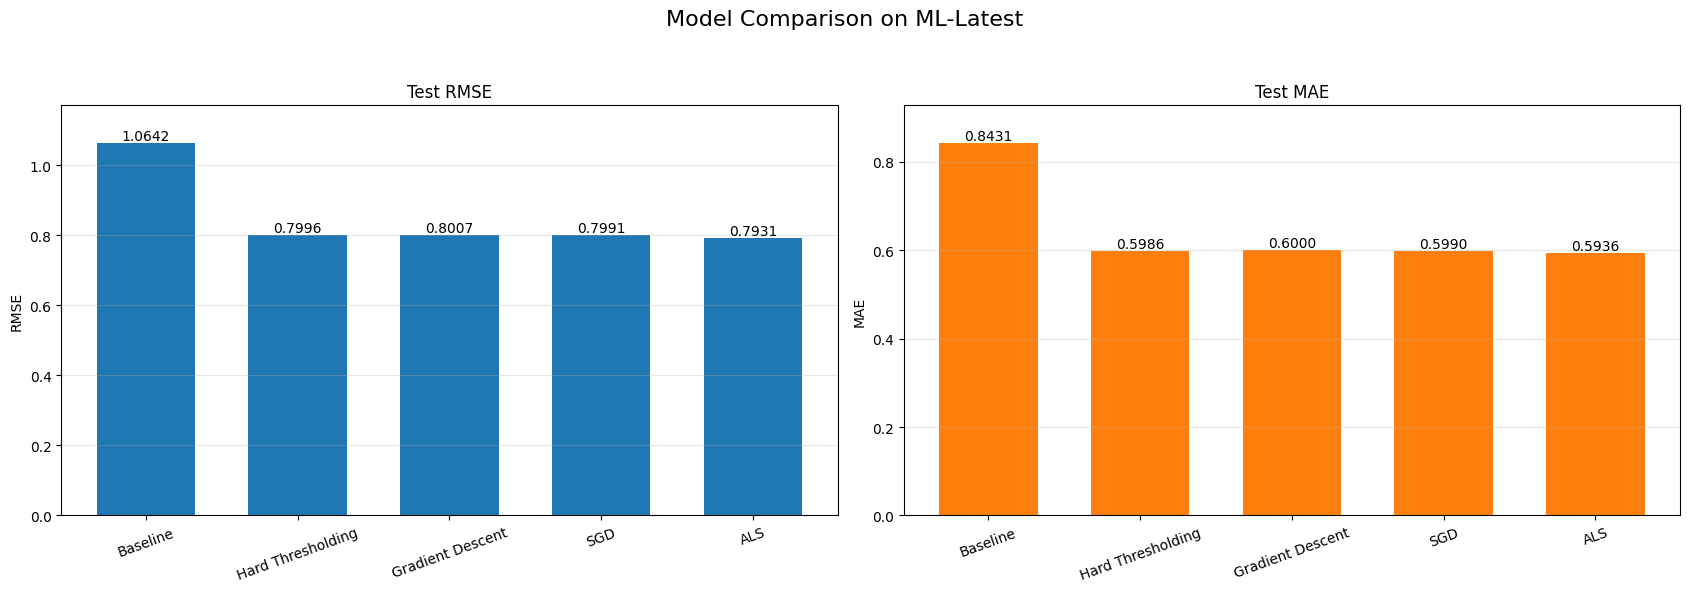

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle('Model Comparison on ML-Latest', fontsize=16)

rmse_bars = axes[0].bar(
    large_results['model'],
    large_results['test_rmse'],
    color='tab:blue',
    width=0.65,
)
axes[0].set_title('Test RMSE')
axes[0].set_ylabel('RMSE')
axes[0].set_ylim(0, large_results['test_rmse'].max() * 1.10)
axes[0].grid(axis='y', alpha=0.3)
axes[0].tick_params(axis='x', rotation=20)
add_value_labels(axes[0], rmse_bars, decimals=4)

mae_bars = axes[1].bar(
    large_results['model'],
    large_results['test_mae'],
    color='tab:orange',
    width=0.65,
)
axes[1].set_title('Test MAE')
axes[1].set_ylabel('MAE')
axes[1].set_ylim(0, large_results['test_mae'].max() * 1.10)
axes[1].grid(axis='y', alpha=0.3)
axes[1].tick_params(axis='x', rotation=20)
add_value_labels(axes[1], mae_bars, decimals=4)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


### Interpretation

All four matrix-completion models substantially improve on the baseline. ALS has the lowest RMSE and MAE. For RMSE, SGD is narrowly ahead of Hard Thresholding; for MAE, Hard Thresholding is narrowly ahead of SGD. Gradient Descent follows very closely.